# Random Forest — Wine Classification

**Goal:** Predict which of **3 wine classes** a sample belongs to, using measurements such as alcohol and flavanoids.

**Teaching sequence:** Load → Split → Baseline → Tune → Test → Interpret.  
**Why `RandomForestClassifier`?** The output is a **category**, not a number.

We use scikit-learn's built-in Wine dataset, so **no CSV download or feature scaling is required**.

## 1. Load the dataset

`X` contains the **13 input features**. `y` contains the target class (0, 1 or 2). Check a few rows before training.

In [1]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import pandas as pd
import matplotlib.pyplot as plt

wine = load_wine(as_frame=True)
X = wine.data
y = wine.target

print("Rows, features:", X.shape)
print("Classes:", wine.target_names)
print("Class counts:", y.value_counts().sort_index())
display(X.head())

Rows, features: (178, 13)
Classes: ['class_0' 'class_1' 'class_2']
Class counts: target
0    59
1    71
2    48
Name: count, dtype: int64


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


## 2. Split into training and test data

Keep the test set separate until the **end**. `stratify=y` helps maintain the class proportions in both groups.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 142
Test rows: 36


## 3. Create a baseline Random Forest

A Random Forest combines predictions from many Decision Trees. We check its **5-fold cross-validation accuracy** using only the training data.

`cross_val_score` creates a fresh model for each fold. The final test data is not used here.

In [3]:
baseline = RandomForestClassifier(n_estimators=100, random_state=42)
baseline_scores = cross_val_score(baseline, X_train, y_train, cv=5, scoring="accuracy")
print("Baseline CV accuracy:", round(baseline_scores.mean(), 3))

Baseline CV accuracy: 0.986


## 4. Tune the important parameters with `GridSearchCV`

- `n_estimators`: Number of trees.
- `max_depth`: Maximum depth of each tree; `None` means no depth limit.
- `min_samples_leaf`: Minimum training rows in each leaf.

GridSearchCV tests **2 × 3 × 2 = 12 combinations** using 5 folds = **60 fits**. It selects the combination with the best average validation accuracy, then refits it on **all training rows**.

In [5]:
param_grid = {
    "n_estimators": [50, 100,150],
    "max_depth": [None, 5, 10],
    "min_samples_leaf": [1, 2, 3, 4, 5]
}

grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    scoring="accuracy",
    cv=5,
    n_jobs=1
)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV accuracy:", round(grid.best_score_, 3))

Best parameters: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 50}
Best CV accuracy: 0.986


## 5. Test the best model once

`best_estimator_` is already fitted on the complete training dataset because `refit=True` by default. Now make predictions for the untouched test records.

In [6]:
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

print("Test accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Classification report:")
print(classification_report(y_test, y_pred, target_names=wine.target_names))

Test accuracy: 1.0
Classification report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      1.00      1.00        14
     class_2       1.00      1.00      1.00        10

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36



## 6. Understand the mistakes

In the confusion matrix, **rows = actual classes** and **columns = predicted classes**. Values on the diagonal are correct predictions.

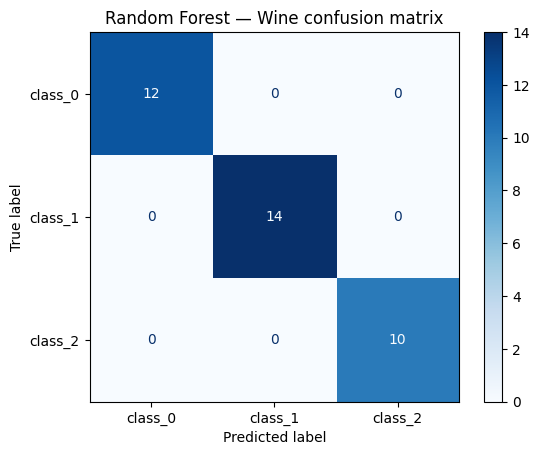

In [6]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=wine.target_names, cmap="Blues"
)
plt.title("Random Forest — Wine confusion matrix")
plt.show()

## 7. Which features did the forest use most?

Feature importance summarizes how much each feature helped reduce impurity across the forest. **Importance does not prove causation.**

In [7]:
importance = pd.Series(best_model.feature_importances_, index=X.columns)
print(importance.sort_values(ascending=False).head(5).round(3))

flavanoids                      0.198
color_intensity                 0.172
proline                         0.144
alcohol                         0.121
od280/od315_of_diluted_wines    0.097
dtype: float64


### Quick student checks

1. Why did we choose a **classifier**, not a regressor?
2. What is the difference between `best_score_` and **test accuracy**?
3. What might happen if every tree is allowed to grow very deep?

**Takeaway:** Tune on training folds; report final performance on the separate test set.